# Konsistenzprüfung der FlipFlop-Nachfrageprognose mit FleetPy

**Fragestellung.** FlipFlop (AIT) prognostiziert, welche Wege bei einem DRT-Angebot zum ÖV-Tarif auf dieses Angebot verlagert würden. Die Prognose beruht auf einer *angenommenen* Bedienqualität (AIT-Dokumentation: Zugangszeit 30 % der ÖV-Zugangszeit von Ø 21 min ≈ **6,3 min**; Fahrzeit zwischen Pkw und ÖV). FleetPy simuliert den Fahrzeugbetrieb für genau diese Nachfrage und misst, welche Bedienqualität eine Flotte tatsächlich liefert. Stimmen angenommene und erreichbare Qualität bei einer realistischen Flotte überein, ist die Prognose in sich konsistent.

**Aufbau.**

| | |
|---|---|
| Netz | GIP-Straßengraph Klagenfurt, 15.320 Knoten / 34.125 gerichtete Kanten, Geschwindigkeiten und Einbahnen je Richtung |
| Echte Nachfrage | KMG/MOIA-Fahrten, 7 Kalendertage einzeln (102–249 Fahrten/Tag), ganzer Tag |
| Prognostizierte Nachfrage | FlipFlop-Umsteiger (DRT zum ÖV-Tarif), alle 5 Ziehungen (je ~2.600 Wege/Tag im Bediengebiet), ganzer Tag |
| Betrieb | Tür-zu-Tür, max. 8 min Wartezeit, 40 % Umweg, Fahrzeugstart nach Dichte echter Fahrtbeginne; zusätzlich Läufe mit garantierter Annahme-Qualität (max. 6,3 min) |
| Umfang | 112 Läufe: Flotten 4–20 (echt) bzw. 20–150 (prognostiziert) |

Die Schwellen für die Annahme-Qualität sind explizite Annahmen, bis AIT absolute Werte je Weg bereitstellt.

Drei Fragen:
1. **Rückrechnung:** Welche Flotte bräuchte es laut FleetPy für die *echten* MOIA-Fahrten? (Kalibrierungsreferenz für KMG)
2. **Dimensionierung:** Welche Flotte bräuchte die FlipFlop-Nachfrage, damit die angenommene Bedienqualität erreicht wird?
3. **Konsistenz:** Verhalten sich prognostizierte und echte Nachfrage bei *gleicher Last pro Fahrzeug* gleich?

In [1]:
import subprocess, sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

ROOT_DIR = Path.cwd().resolve()
while ROOT_DIR.name != 'FleetPy' and ROOT_DIR.parent != ROOT_DIR:
    ROOT_DIR = ROOT_DIR.parent
STUDY = ROOT_DIR / 'studies' / 'flipflop_drt_integration_pilot'

BLUE = '#2a78d6'    # MOIA / KMG (echt)
ORANGE = '#eb6834'  # FlipFlop (prognostiziert)
INK, MUTED = '#0b0b0b', '#52514e'
plt.rcParams.update({'font.size': 13, 'axes.edgecolor': '#c9c8c2', 'axes.labelcolor': INK, 'text.color': INK,
                     'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e7e6e1', 'grid.linewidth': 0.8, 'figure.facecolor': 'white',
                     'axes.facecolor': 'white'})

WAIT_ASSUMED_MIN = 6.3   # 0.3 x 21 min PT access (AIT README) -- Annahme, von AIT zu bestaetigen
DETOUR_ASSUMED = 1.4     # Fahrzeit <= 1.4 x Direktfahrt            -- Annahme, von AIT zu bestaetigen

subprocess.run([sys.executable, str(STUDY / 'evaluate_v2.py'), '--pattern', 'v2*',
                '--wait-threshold-min', str(WAIT_ASSUMED_MIN), '--detour-threshold', str(DETOUR_ASSUMED)],
               check=True, capture_output=True)
ev = pd.read_csv(STUDY / 'results' / 'v2_evaluation.csv')
ev['variant'] = ev['variant'].fillna('')
ev = ev[ev['source'].isin(['moia', 'ff']) & ~ev['scenario'].str.contains('probe')].copy()
ev['load'] = ev['requests'] / ev['fleet']   # Anfragen pro Fahrzeug und Tag
base = ev[ev['variant'] == '']               # Standard-Betrieb: max. 8 min Wartezeit erlaubt
w6 = ev[ev['variant'] == 'w6']               # Betrieb auf die AIT-Annahme konfiguriert: max. 6.3 min Wartezeit
moia, ff = base[base.source == 'moia'], base[base.source == 'ff']
print(f"{len(moia)} MOIA-Laeufe (Tage x Flotten), {len(ff)} FlipFlop-Laeufe (Ziehungen x Flotten)")
print(f"MOIA: {moia.requests.min()}-{moia.requests.max()} Anfragen/Tag; FlipFlop: {ff.requests.min()}-{ff.requests.max()} Umsteiger/Tag")

42 MOIA-Laeufe (Tage x Flotten), 30 FlipFlop-Laeufe (Ziehungen x Flotten)
MOIA: 102-249 Anfragen/Tag; FlipFlop: 2549-2728 Umsteiger/Tag


## 1. Rückrechnung: Welche Flotte brauchen die echten MOIA-Fahrten?

Jeder der 7 Kalendertage wird einzeln simuliert (104–259 Fahrten/Tag). Die Flotte, ab der ≥ 90 % der Fahrten bedient werden, ist die **implizite Flotte** — eine Zahl, die KMG mit der tatsächlichen Flotte abgleichen kann. Stimmt sie grob, ist der Simulator für Klagenfurt kalibriert; weicht sie stark ab, wissen wir, wo nachzujustieren ist (Betriebsregeln, Geschwindigkeiten, Fahrzeugstandorte).

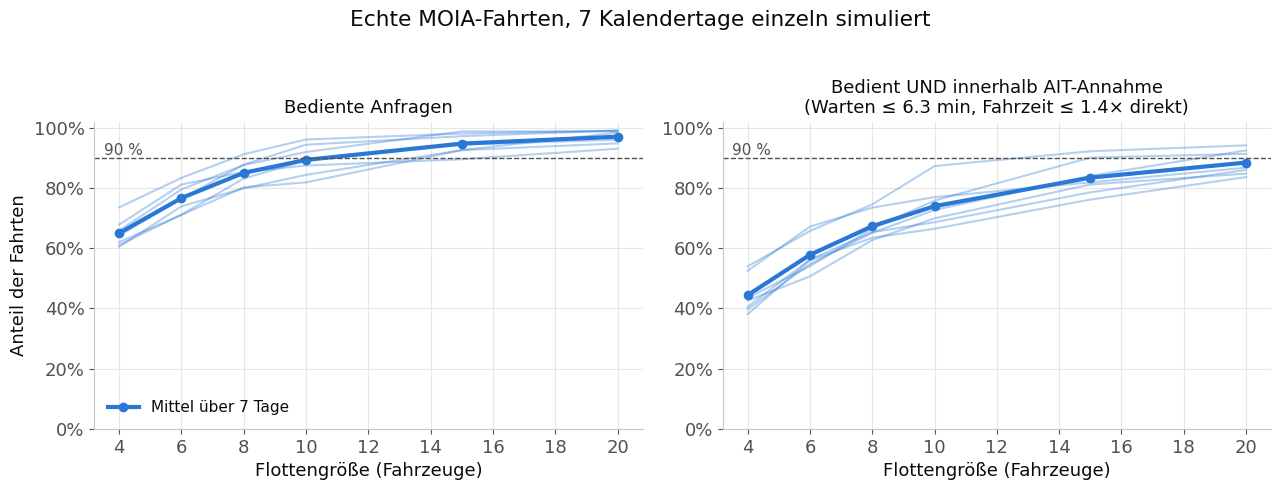

      Anfragen  Flotte für ≥90 % bedient  Flotte für ≥80 % innerhalb Annahme
set                                                                         
day0       102                         8                                  10
day1       106                        10                                  15
day2       121                        15                                  20
day3       134                        15                                  20
day4       161                        10                                  15
day5       249                        15                                  15
day6       143                        20                                  15

Implizite Flotte (≥90 % bedient): 8-20 Fahrzeuge je nach Tag


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for day, g in moia.groupby('set'):
    g = g.sort_values('fleet')
    axes[0].plot(g.fleet, g.served_pct, color=BLUE, alpha=0.35, lw=1.5)
    axes[1].plot(g.fleet, g.served_within_assumed_los_pct, color=BLUE, alpha=0.35, lw=1.5)
m = moia.groupby('fleet')[['served_pct', 'served_within_assumed_los_pct']].mean()
axes[0].plot(m.index, m.served_pct, color=BLUE, lw=3, marker='o', label='Mittel über 7 Tage')
axes[1].plot(m.index, m.served_within_assumed_los_pct, color=BLUE, lw=3, marker='o', label='Mittel über 7 Tage')
for ax, title in zip(axes, ['Bediente Anfragen', f'Bedient UND innerhalb AIT-Annahme\n(Warten ≤ {WAIT_ASSUMED_MIN} min, Fahrzeit ≤ {DETOUR_ASSUMED}× direkt)']):
    ax.axhline(90, color=MUTED, ls='--', lw=1)
    ax.text(ax.get_xlim()[0] + 0.3, 91, '90 %', color=MUTED, fontsize=11)
    ax.set_xlabel('Flottengröße (Fahrzeuge)'); ax.set_ylim(0, 102)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter()); ax.set_title(title, fontsize=13)
axes[0].set_ylabel('Anteil der Fahrten'); axes[0].legend(frameon=False, fontsize=11)
fig.suptitle('Echte MOIA-Fahrten, 7 Kalendertage einzeln simuliert', y=1.02); fig.tight_layout(); plt.show()

implied = (moia.sort_values('fleet').groupby('set')[['requests', 'fleet', 'served_pct', 'served_within_assumed_los_pct']]
           .apply(lambda g: pd.Series({'Anfragen': int(g.requests.iloc[0]),
                                       'Flotte für ≥90 % bedient': g.loc[g.served_pct >= 90, 'fleet'].min(),
                                       'Flotte für ≥80 % innerhalb Annahme': g.loc[g.served_within_assumed_los_pct >= 80, 'fleet'].min()})))
print(implied.to_string())
print(f"\nImplizite Flotte (≥90 % bedient): {implied['Flotte für ≥90 % bedient'].min():.0f}-{implied['Flotte für ≥90 % bedient'].max():.0f} Fahrzeuge je nach Tag")

**Rückfrage an KMG:** Wie viele Fahrzeuge waren an diesen Tagen tatsächlich im Einsatz, und welche Wartezeiten wurden erreicht? Liegt die echte Flotte in der Größenordnung der impliziten Flotte, ist der Simulator belastbar. (Die Tage sind im Datensatz nur relativ nummeriert; der Zeitraum müsste von KMG benannt werden.)

## 2. Dimensionierung: Welche Flotte braucht die FlipFlop-Nachfrage?

Die 5 Ziehungen liefern je ~2.550–2.730 Umsteiger pro Tag (gesamter Tag, MOIA-Rahmen). Gezeigt werden Mittelwert und Spannweite über die Ziehungen.

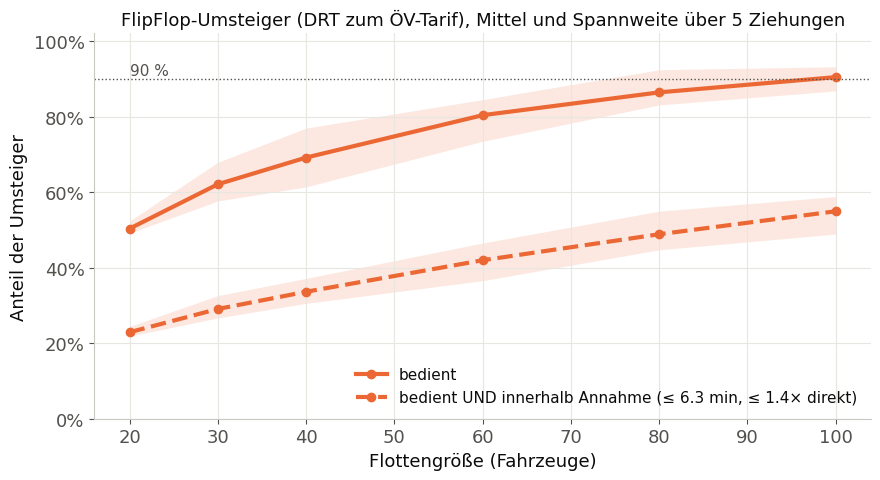

       Anfragen  bedient  innerhalb_Annahme  Wartezeit_Median_min  Wartezeit_p90_min  Umweg_Median  Fahrten_pro_Fzg_Stunde  Auslastung
fleet                                                                                                                                 
20       2601.2     50.3               22.9                   6.0                7.7           1.2                     5.2        52.4
30       2601.2     62.1               29.1                   5.9                7.7           1.2                     5.3        42.6
40       2601.2     69.1               33.6                   5.7                7.7           1.2                     5.3        35.3
60       2601.2     80.3               42.0                   5.4                7.6           1.2                     5.4        26.9
80       2601.2     86.4               48.8                   5.0                7.6           1.2                     5.5        21.4
100      2601.2     90.4               54.9            

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))
for col, label, ls in [('served_pct', 'bedient', '-'), ('served_within_assumed_los_pct', f'bedient UND innerhalb Annahme (≤ {WAIT_ASSUMED_MIN} min, ≤ {DETOUR_ASSUMED}× direkt)', '--')]:
    g = ff.groupby('fleet')[col].agg(['mean', 'min', 'max'])
    ax.fill_between(g.index, g['min'], g['max'], color=ORANGE, alpha=0.15, lw=0)
    ax.plot(g.index, g['mean'], color=ORANGE, lw=3, ls=ls, marker='o', label=label)
ax.axhline(90, color=MUTED, ls=':', lw=1); ax.text(ff.fleet.min(), 91, '90 %', color=MUTED, fontsize=11)
ax.set_xlabel('Flottengröße (Fahrzeuge)'); ax.set_ylabel('Anteil der Umsteiger'); ax.set_ylim(0, 102)
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.set_title('FlipFlop-Umsteiger (DRT zum ÖV-Tarif), Mittel und Spannweite über 5 Ziehungen', fontsize=13)
ax.legend(frameon=False, fontsize=11, loc='lower right'); fig.tight_layout(); plt.show()

tab = ff.groupby('fleet').agg(Anfragen=('requests', 'mean'), bedient=('served_pct', 'mean'), innerhalb_Annahme=('served_within_assumed_los_pct', 'mean'),
                              Wartezeit_Median_min=('wait_median_min', 'mean'), Wartezeit_p90_min=('wait_p90_min', 'mean'),
                              Umweg_Median=('detour_median', 'mean'), Fahrten_pro_Fzg_Stunde=('rides_per_veh_h', 'mean'),
                              Auslastung=('fleet_util_pct', 'mean')).round(1)
print(tab.to_string())
f90 = tab.index[tab.bedient >= 90].min() if (tab.bedient >= 90).any() else None
f80 = tab.index[tab.innerhalb_Annahme >= 80].min() if (tab.innerhalb_Annahme >= 80).any() else None
print(f"\nKleinste getestete Flotte mit ≥90 % bedient: {f90}; mit ≥80 % innerhalb der AIT-Annahme: {f80}  (None = im getesteten Bereich nicht erreicht)")

**Lesart:** Die Kurve „bedient" sagt, ob die Nachfrage überhaupt abgefahren werden kann; die Kurve „innerhalb Annahme" sagt, ob sie *so gut* bedient wird, wie FlipFlop es bei der Prognose vorausgesetzt hat. Die Lücke zwischen beiden ist der Teil der Nachfrage, der zwar mitgenommen würde, aber mit schlechterer Qualität als angenommen — ein Teil dieser Personen würde im Modell nicht umsteigen. Je größer die Lücke bei der realistisch finanzierbaren Flotte, desto stärker ist die Prognose nach unten zu korrigieren (Iteration mit AIT).

## 3. Konsistenz: Verhalten sich beide Nachfragen bei gleicher Last gleich?

Flottengröße allein ist keine faire Achse (2.600 vs. 100–260 Anfragen). Vergleichbar ist die **Last pro Fahrzeug** (Anfragen je Fahrzeug und Tag). Liegen die FlipFlop-Punkte auf der MOIA-Kurve, ist die prognostizierte Nachfrage räumlich-zeitlich so „poolbar" wie echte Nachfrage; liegen sie darunter oder darüber, verhält sie sich systematisch anders.

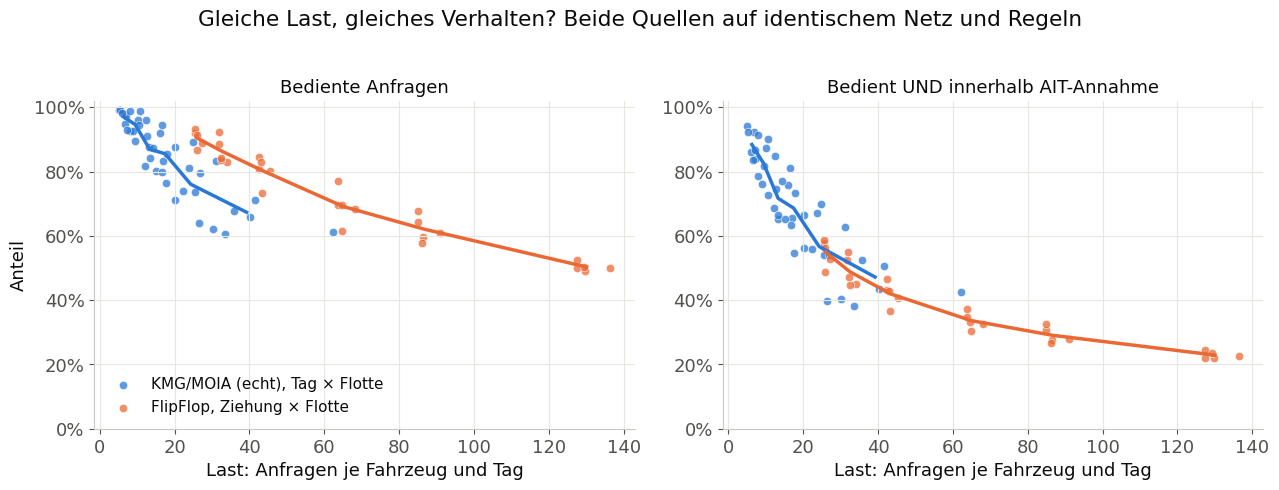

Überlappender Lastbereich: 25-62 Anfragen/Fahrzeug/Tag
  MOIA     (10 Läufe): bedient 69 %, innerhalb Annahme 48 %, Wartezeit-Median 4.8 min, Umweg 1.07
  FlipFlop (15 Läufe): bedient 86 %, innerhalb Annahme 49 %, Wartezeit-Median 5.0 min, Umweg 1.21


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharex=True)
for ax, col, title in zip(axes, ['served_pct', 'served_within_assumed_los_pct'], ['Bediente Anfragen', 'Bedient UND innerhalb AIT-Annahme']):
    ax.scatter(moia.load, moia[col], color=BLUE, s=36, alpha=0.75, label='KMG/MOIA (echt), Tag × Flotte', edgecolor='white', lw=0.5)
    ax.scatter(ff.load, ff[col], color=ORANGE, s=36, alpha=0.75, label='FlipFlop, Ziehung × Flotte', edgecolor='white', lw=0.5)
    for src, color in [(moia, BLUE), (ff, ORANGE)]:
        order = np.argsort(src.load.values); x, y = src.load.values[order], src[col].values[order]
        if len(x) > 3:
            bins = np.quantile(x, np.linspace(0, 1, 7)); idx = np.clip(np.digitize(x, bins) - 1, 0, 5)
            xb = [x[idx == i].mean() for i in range(6) if (idx == i).any()]; yb = [y[idx == i].mean() for i in range(6) if (idx == i).any()]
            ax.plot(xb, yb, color=color, lw=2.5)
    ax.set_xlabel('Last: Anfragen je Fahrzeug und Tag'); ax.set_ylim(0, 102); ax.set_title(title, fontsize=13)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter())
axes[0].set_ylabel('Anteil'); axes[0].legend(frameon=False, fontsize=11, loc='lower left')
fig.suptitle('Gleiche Last, gleiches Verhalten? Beide Quellen auf identischem Netz und Regeln', y=1.02); fig.tight_layout(); plt.show()

lo, hi = max(moia.load.min(), ff.load.min()), min(moia.load.max(), ff.load.max())
ov_m, ov_f = moia[moia.load.between(lo, hi)], ff[ff.load.between(lo, hi)]
print(f"Überlappender Lastbereich: {lo:.0f}-{hi:.0f} Anfragen/Fahrzeug/Tag")
print(f"  MOIA     ({len(ov_m)} Läufe): bedient {ov_m.served_pct.mean():.0f} %, innerhalb Annahme {ov_m.served_within_assumed_los_pct.mean():.0f} %, Wartezeit-Median {ov_m.wait_median_min.mean():.1f} min, Umweg {ov_m.detour_median.mean():.2f}")
print(f"  FlipFlop ({len(ov_f)} Läufe): bedient {ov_f.served_pct.mean():.0f} %, innerhalb Annahme {ov_f.served_within_assumed_los_pct.mean():.0f} %, Wartezeit-Median {ov_f.wait_median_min.mean():.1f} min, Umweg {ov_f.detour_median.mean():.2f}")

## 4. Gegenprobe: Dienst direkt auf die AIT-Annahme konfiguriert

In den Abschnitten 1–3 *darf* der Betreiber bis zu 8 min Wartezeit einplanen; „innerhalb Annahme" wird nachträglich gemessen. Sauberer ist die Umkehrung: Der Dienst wird mit **max. 6,3 min Wartezeit** betrieben (`op_max_wait_time = 378 s`), und gemessen wird, welcher Anteil der Nachfrage bei dieser Qualität überhaupt bedient werden kann. Alles, was dann nicht bedient wird, hätte im FlipFlop-Modell nicht die angenommene Qualität bekommen.

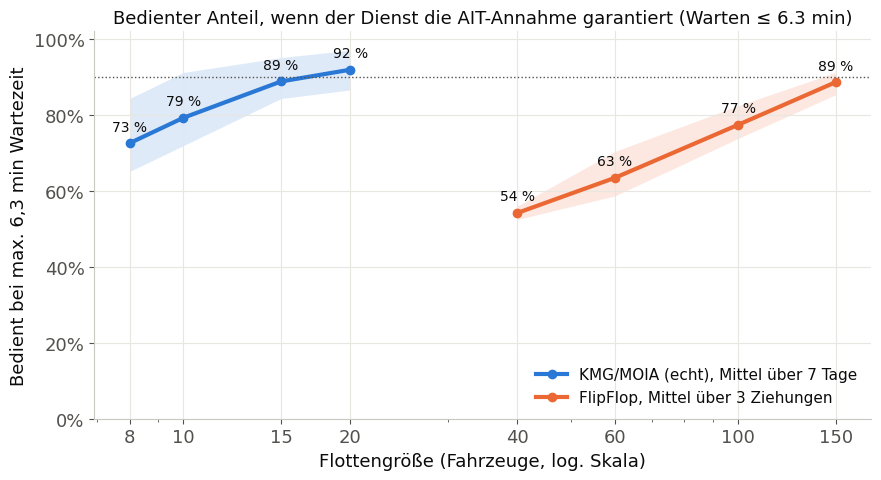

              Anfragen  bedient  bedient_min  bedient_max  Wartezeit_Median_min  Umweg_Median  Fahrten_pro_Fzg_Stunde  Auslastung
source fleet                                                                                                                     
ff     40       2623.7     54.2         52.5         56.0                   4.4           1.2                     5.3        28.2
       60       2623.7     63.4         58.7         70.4                   4.2           1.2                     5.3        21.9
       100      2623.7     77.4         73.8         82.4                   3.8           1.2                     5.4        15.6
       150      2623.7     88.6         85.3         91.2                   3.0           1.2                     5.6        11.6
moia   8         145.1     72.6         65.1         84.3                   3.8           1.1                     4.9        11.2
       10        145.1     79.2         71.9         91.2                   3.4           

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
for src, color, label in [('moia', BLUE, 'KMG/MOIA (echt), Mittel über 7 Tage'), ('ff', ORANGE, 'FlipFlop, Mittel über 3 Ziehungen')]:
    g = w6[w6.source == src].groupby('fleet')['served_pct'].agg(['mean', 'min', 'max'])
    if len(g):
        ax.fill_between(g.index, g['min'], g['max'], color=color, alpha=0.15, lw=0)
        ax.plot(g.index, g['mean'], color=color, lw=3, marker='o', label=label)
        for f, v in g['mean'].items():
            ax.annotate(f'{v:.0f} %', (f, v), textcoords='offset points', xytext=(0, 9), ha='center', fontsize=10, color=INK)
ax.axhline(90, color=MUTED, ls=':', lw=1)
ax.set_xscale('log'); ax.set_xticks([8, 10, 15, 20, 40, 60, 100, 150]); ax.get_xaxis().set_major_formatter(mticker.ScalarFormatter())
ax.set_xlabel('Flottengröße (Fahrzeuge, log. Skala)'); ax.set_ylabel('Bedient bei max. 6,3 min Wartezeit'); ax.set_ylim(0, 102)
ax.yaxis.set_major_formatter(mticker.PercentFormatter()); ax.legend(frameon=False, fontsize=11, loc='lower right')
ax.set_title(f'Bedienter Anteil, wenn der Dienst die AIT-Annahme garantiert (Warten ≤ {WAIT_ASSUMED_MIN} min)', fontsize=13)
fig.tight_layout(); plt.show()

t = w6.groupby(['source', 'fleet']).agg(Anfragen=('requests', 'mean'), bedient=('served_pct', 'mean'), bedient_min=('served_pct', 'min'), bedient_max=('served_pct', 'max'),
                                       Wartezeit_Median_min=('wait_median_min', 'mean'), Umweg_Median=('detour_median', 'mean'),
                                       Fahrten_pro_Fzg_Stunde=('rides_per_veh_h', 'mean'), Auslastung=('fleet_util_pct', 'mean')).round(1)
print(t.to_string())
ffw = t.loc['ff'] if 'ff' in t.index.get_level_values(0) else None
if ffw is not None:
    print(f"\nFlipFlop: bei garantierter Annahme-Qualität werden mit 40/60/100/150 Fahrzeugen "
          + ' / '.join(f'{v:.0f} %' for v in ffw.bedient) + ' der prognostizierten Umsteiger bedient.')

## Einordnung und offene Punkte

**Was dieser Test leistet:** Er prüft die *innere Konsistenz* der FlipFlop-Prognose (angenommene vs. erreichbare Bedienqualität) und ob die prognostizierte Nachfrage operativ so behandelbar ist wie echte Nachfrage. Er prüft **nicht**, ob die vorhergesagten Personen wirklich umsteigen würden — das kann nur der Betrieb zeigen.

**Explizite Annahmen (zu bestätigen):**
- AIT: absolute Bedienqualitäts-Annahmen pro Weg (Zugangsminuten, Fahrzeit) — hier als 6,3 min Wartezeit und 1,4× Direktfahrzeit operationalisiert.
- Service-Definition: Tür-zu-Tür, max. 8 min Wartezeit, 40 % Umweg, keine Vorbuchung, Fahrzeuge starten nach Dichte der echten MOIA-Starts, keine aktive Umpositionierung. Betriebszeit: ganzer Tag.
- Gebiet: Bounding Box der echten MOIA-Fahrten als Ersatz für das (noch nicht gemeinsam definierte) Bediengebiet.
- MOIA-Daten: 7 Kalendertage, Zeitraum und Flotte unbekannt → Rückfrage an KMG.

**Nächste Schritte:** (1) implizite Flotte mit KMG abgleichen, (2) absolute Annahmen von AIT einholen und die Schwellen ersetzen, (3) bei großer Lücke in Abschnitt 2 eine Iterationsrunde mit AIT (erreichte Bedienqualität → neue Nachfrage), (4) Preisszenarien Kostenx0,5 / x2 mit derselben Kette.